# KQC SingleXmons — six Swissmons on one feedline (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/single_xmons.py` (class `SingleXmons`; © 2021 IQM Finland Oy, GPL-3.0,
<https://github.com/iqm-finland/KQCircuits>; local copy `other-libs/KQCircuits-main/.../kqcircuits/chips/single_xmons.py`).
Six Swissmon qubits, three above and three below a horizontal feedline from launcher WN to launcher ES of an
SMA8 sample holder. Each qubit has a λ/4 readout resonator (5000 … 5500 µm) coupled to the feedline over a
450 µm hanger section, and a charge line from its own launcher. Four test resonators (5200 … 5800 µm) hang off
the feedline through finger / gap capacitors on T-splitters, and four junction test-pad arrays sit on the chip
edges.

This notebook **rebuilds** the chip with our components, routes, netlist and LOM on the Quantcore PDK (not a
replica); we distribute the rebuild under GPL-3.0.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm (SMA8 launchers on its edges), Quantcore die frame, device ID "SXMONS" |
| launchers | SMA8, `launcher_indent` 800 µm (outer etch 20 µm from the edge) | SMA8, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm, 80 µm further in than KQC's) |
| substrate | silicon εr 11.45 (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junctions | KQC Manhattan SQUIDs (assumed L_J 16 nH) | Quantcore trilayer SQUIDs, 2 × 0.25 × 0.6 µm, R_n 45 kΩ in parallel, L_J 6.73 nH |
| cheese | KQC's whole-area ground grid (`with_grid`) | **the original wins:** KQC's grid (`with_grid=True`), no PDK band |
| readout couplers | 400 µm straight + bend, 27 µm from the feedline centre (5 µm ground strip) | same centres, now given as `near=(x, y)` points on the feedline (they no longer slide when the launchers move) |
| placement | centred | centred (no shift) |

**Kept exactly:** the six `Swissmon`s (arm 146 µm, coupler 1 of 140 µm, no flux line, charge-line offset
200 µm) at the KQC positions and rotations; the feedline path WN → (2000, y_WN) → (2000, 5000) → (8000, 5000) →
(8000, y_ES) → ES; the four tees and capacitors (`cap_params(4, 23.1)`, `(4, 9.9)`, `(2, 14.1)` interdigital and
`(4, 10)` gap); the test-resonator paths and lengths; the charge lines with their 6 µm open end; the four
`JunctionTestPads` arrays; the readout lengths and the 27 µm coupling.

**Simplified:** each readout is a qcc *hanger* route: qubit → meander → 450 µm coupler → shorted end (KQC puts
the meander after the coupler); same λ/4 topology and length, slightly different footprint. The test-resonator
meanders are fitted by the router instead of KQC's fixed 250 µm-wide `Meander`.

**Fixed here:** the pad rule moves the launchers in (80 µm with today's 100 µm rule), and KQC's hard-coded
arclengths (`s = x + 1400` along the first feedline segment) slid RR3's coupler with them: already the 5 µm of
the first, 25 µm rule left a 5 µm segment the router could not bend. The couplers are now anchored by position
(`near=`) and the feedline's corners by the launcher ports, so they stay at KQC's positions whatever the indent.

## 1 · Setup

`LIVE` follows `QCC_LIVE`; `RUN_FEM = False` keeps the FEM step at "export only" (True: solve in a new batch
AEDT 2024 R1, if installed); `FULL_FAB = False` skips corner rounding of the grid holes in the fab step.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")
STEPS = Path("build/snapshots/singlexmons")      # step-by-step snapshots (not kept in the repo)

## 2 · The PDK this chip uses

The stack feeds the LOM estimates and FEM exports, the frame and pad rule shape the die, the junction rule sizes
the SQUIDs, the cheese / 3/0 / rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junction.** KQC draws a SQUID in every Swissmon; `trilayer_junction` makes it the Quantcore trilayer SQUID
at the PDK nominal L_J (two 0.25 × 0.6 µm junctions, 45 kΩ in parallel). KQC's `junction_width` carries the
straight finger; `JUNCTION` (L_J, C_J) goes to the LOM and the FEM junction ports.

In [4]:
LJ_PDK = trilayer_junction("Swissmon")[1]["Lj_nH"]          # PDK nominal L_J (0.5 × 0.6 µm junction, R_n 45 kΩ)
JJ_PARAMS, JUNCTION = trilayer_junction("Swissmon", lj_nH=LJ_PDK, squid=True)
print("cell parameters:", JJ_PARAMS, "| LOM junction:", JUNCTION)

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_width': 0.25} | LOM junction: {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


## 3 · The die and its frame

10 × 10 mm with the SMA8 sample holder's eight launchers (NW, NE, EN, ES, SE, SW, WS, WN), the chip name
"SXMONS" as device ID, and KQC's whole-area ground grid (`with_grid=True`: the original's cheese, so the PDK band
is not added). The Quantcore frame (dicing L's, alignment grids, boundary) replaces KQC's ChipFrame.

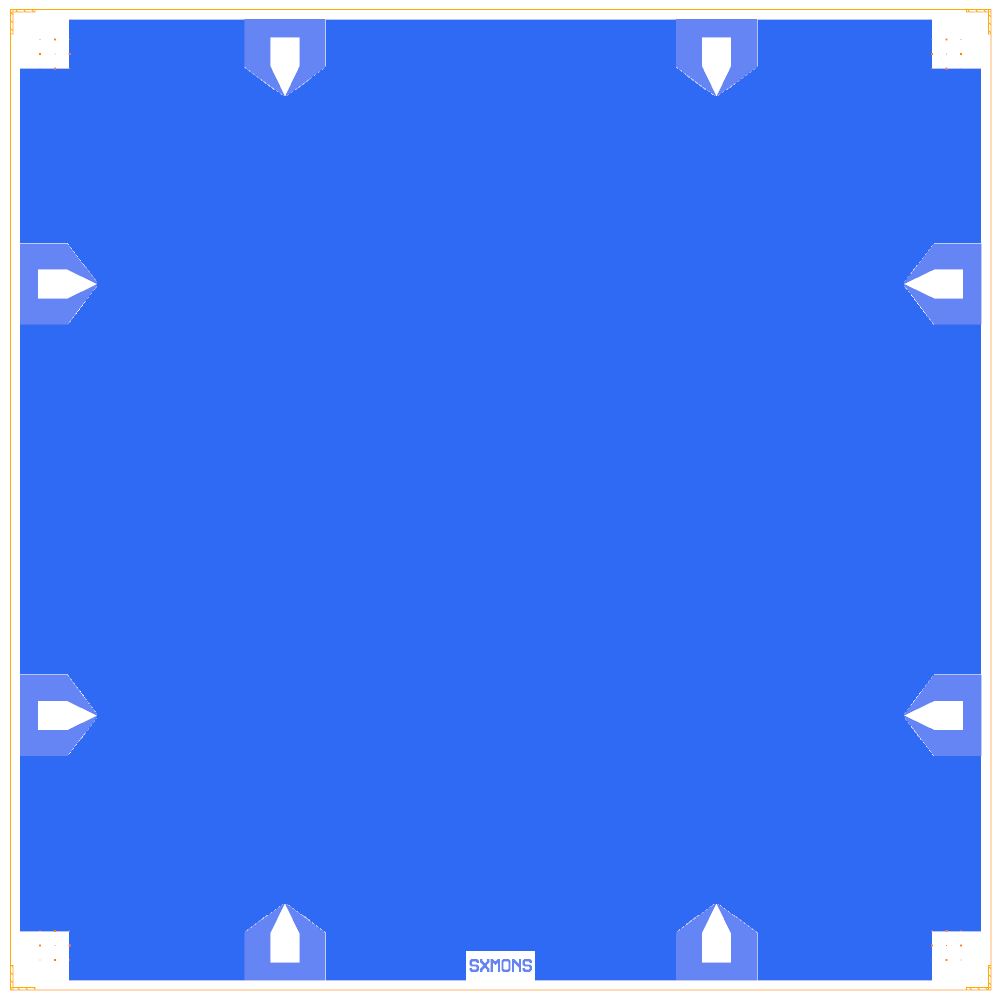

In [5]:
d = Designer("singlexmons", box=(0, 0, 10000, 10000), launchers="SMA8",
             chip={"name_chip": "SXMONS", "with_grid": True}, live=LIVE)
snap(d, STEPS / "1_die.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 4 · Launchers and the pad rule

The PDK puts a launcher's outer etch edge `frame.pad_edge` (100 µm) from the die edge: for SMA8 (RF launcher, 300 µm taper + 300 µm
pad + 180 µm frame gap) the Designer sets `launcher_indent` = 100 + 300 + 300 + 180 = **880 µm** (KQC: 800). Every
route that starts at a launcher takes its waypoints from the launcher's port (`port_xy(d, "chip.WN")`), so the
80 µm shift needs no other change.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.NW | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.NE | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.EN | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.ES | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.SE | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.SW | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.WS | launcher port | w | port 880 µm in (indent from the rule) | ✓ |
| chip.WN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

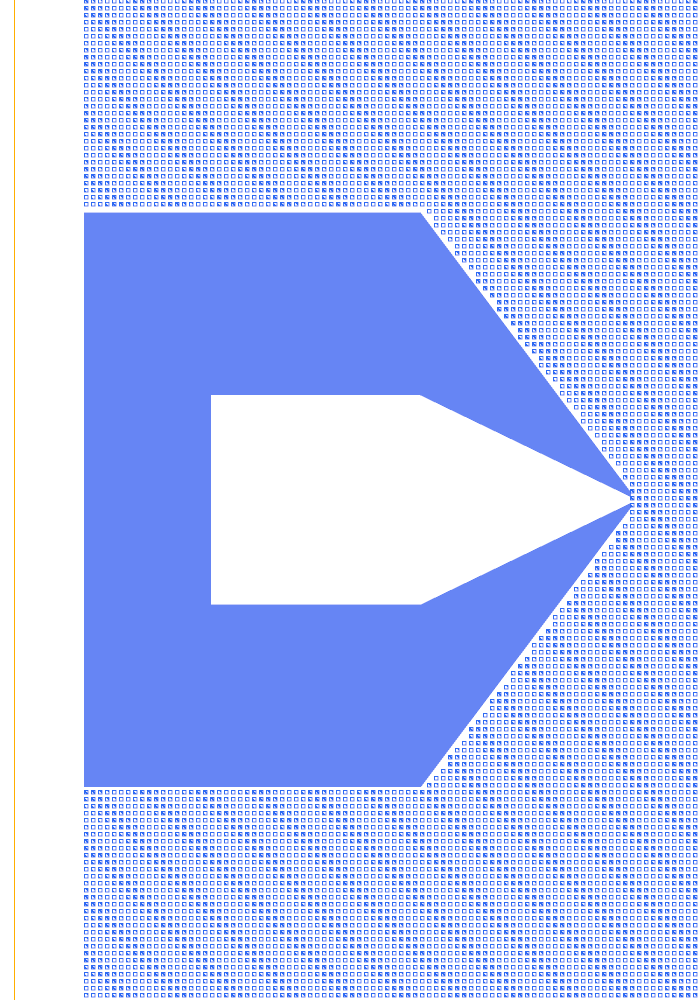

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, "chip.WN")
snap(d, STEPS / "2_launcher.png", box=(-20, y - 400, x + 100, y + 400), size=(700, 1000), width=300);

## 5 · Components

**Junction test arrays** (KQC `Chip.produce_junction_tests`): four `JunctionTestPads` areas on the edges, with
the same trilayer SQUID.

**Qubits.** Six `Swissmon`s: QB0–QB2 above the feedline (rotated 180°), QB3–QB5 below; arms 146 µm wide 24 µm,
gap 24 µm, only coupler 1 (140 µm long, 24 µm wide, 102 µm gap) towards the feedline, no flux line, charge-line
offset 200 µm. Ports: `cplr0`–`cplr2`, `drive` (plus `flux`, unused here).

**Feedline tees and test capacitors.** Four `WaveguideCoplanarSplitter` tees on the feedline (y = 5000), each
with a `FingerCapacitorSquare` snapped to its bottom port: interdigital `cap_params(4, 23.1)`, `(4, 9.9)`,
`(2, 14.1)` and a gap capacitor `(4, 10)` — KQC's `cap_params`.

<Swissmon QB0 ports=['cplr0', 'cplr1', 'cplr2', 'drive']>


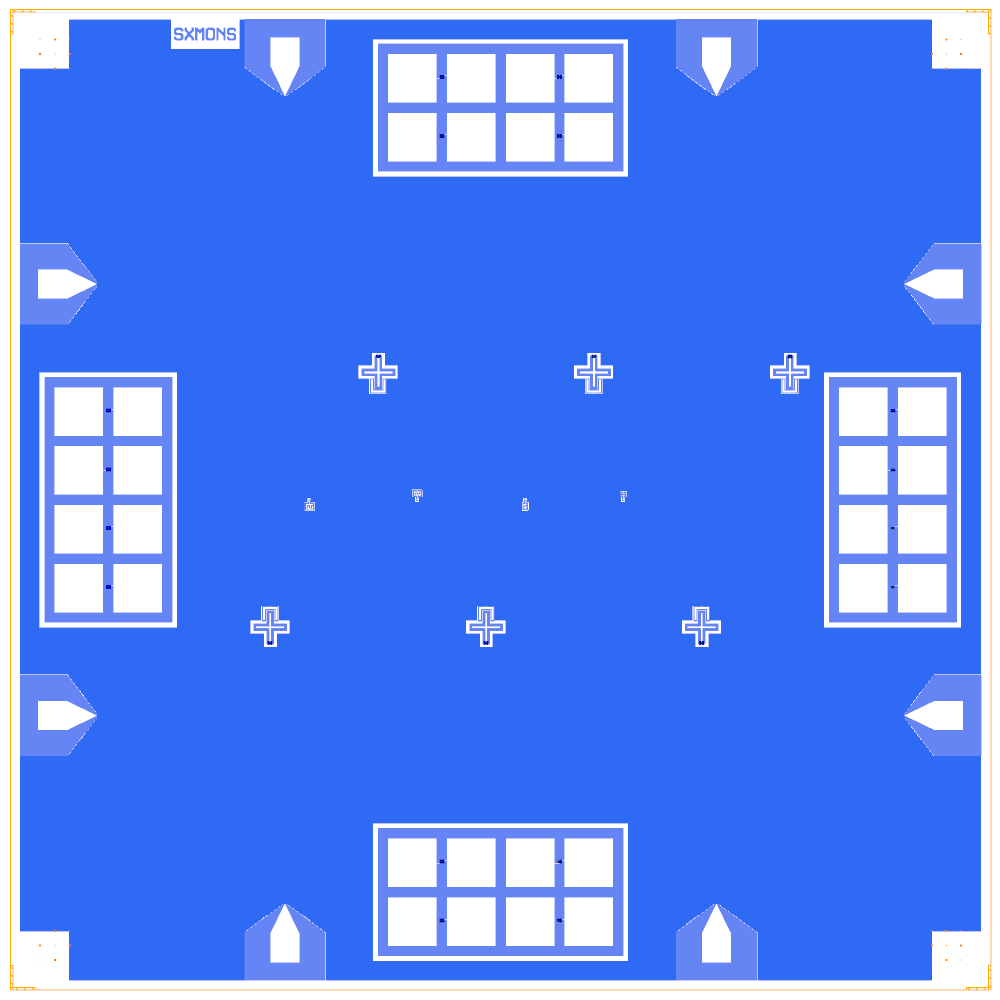

In [7]:
with d.batch():
    JTP = "kqcircuits.test_structures.junction_test_pads.junction_test_pads.JunctionTestPads"
    for name, at, (w, h) in (("JT_W", (350, 3750), (1300, 2500)), ("JT_S", (3750, 350), (2500, 1300)),
                             ("JT_E", (8350, 3750), (1300, 2500)), ("JT_N", (3750, 8350), (2500, 1300))):
        d.add(name, JTP, at=at, margin=50, area_width=w, area_height=h, junctions_horizontal=True, **JJ_PARAMS)

    swissmon = dict(fluxline_type="none", arm_length=[146] * 4, arm_width=[24] * 4, gap_width=[24] * 4, island_r=2,
                    cpl_length=[0, 140, 0], cpl_width=[60, 24, 60], cpl_gap=[110, 102, 110], cl_offset=[200, 200])
    cx, sx, sy = 5400, 1100, 2600
    qpos = {"QB0": (cx - 1.5 * sx, 5000 + sy / 2, 180), "QB1": (cx + 0.5 * sx, 5000 + sy / 2, 180),
            "QB2": (cx + 2.5 * sx - 200, 5000 + sy / 2, 180), "QB3": (cx - 2.5 * sx, 5000 - sy / 2, 0),
            "QB4": (cx - 0.5 * sx, 5000 - sy / 2, 0), "QB5": (cx + 1.5 * sx, 5000 - sy / 2, 0)}
    qb = {n: d.add(n, "Swissmon", at=(x, y), rot=r, junction=JUNCTION, **JJ_PARAMS, **swissmon)
          for n, (x, y, r) in qpos.items()}

    tee_x = [(qpos["QB3"][0] + qpos["QB4"][0]) / 2 - 700, (qpos["QB1"][0] + qpos["QB0"][0]) / 2 - 700,
             (qpos["QB5"][0] + qpos["QB4"][0]) / 2 - 700, (qpos["QB2"][0] + qpos["QB1"][0]) / 2 - 700]
    caps = [dict(finger_number=4, finger_length=23.1, finger_gap_end=5, finger_gap=5, finger_width=15),
            dict(finger_number=4, finger_length=9.9, finger_gap_end=5, finger_gap=5, finger_width=15),
            dict(finger_number=2, finger_length=14.1, finger_gap_end=5, finger_gap=5, finger_width=15),
            dict(finger_number=4, finger_length=0, finger_gap_end=10, finger_gap=0, finger_width=10)]  # "gap"
    tee = [d.add(f"T{i}", "WaveguideCoplanarSplitter", at=(x, 5000), rot=180 * (i % 2), lengths=[11, 11, 31],
                 port_names=["right", "left", "bottom"]) for i, x in enumerate(tee_x)]
    cap = [d.add(f"C{i}", "FingerCapacitorSquare", snap="b", to=tee[i].bottom, ground_padding=10, **caps[i])
           for i in range(4)]
print(qb["QB0"])
snap(d, STEPS / "3_components.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 6 · Routes

**Feedline** WN → T0 → T1 → T2 → T3 → ES in five CPW routes (KQC joins the tees right / left alternately). Its
two corners take their y from the launcher ports.

**Test resonators** from each capacitor: 300 µm out, 500 µm sideways, 100 µm, then a meander as tall as KQC's
250 µm-wide one, ending short (`d.free_end(..., term=0)`); bend radius 50 µm.

In [8]:
_, y_wn = port_xy(d, "chip.WN")
_, y_es = port_xy(d, "chip.ES")
with d.batch():
    d.route("FL0", "chip.WN", tee[0].left, nodes=[(2000, y_wn), (2000, 5000)])
    d.route("FL1", tee[0].right, tee[1].right)
    d.route("FL2", tee[1].left, tee[2].left)
    d.route("FL3", tee[2].right, tee[3].right)
    d.route("FL4", tee[3].left, "chip.ES", nodes=[(8000, 5000), (8000, y_es)])
    for i, length in enumerate([5200, 5400, 5600, 5800]):
        f = 2 * (i % 2) - 1                                   # -1: below the feedline, +1: above
        x, y = port_xy(d, f"C{i}.a")
        h = 2 * 50 * (kqc_meanders(length - 857, 50, 250) + 1)  # 857 µm: the non-meander part with its two bends
        d.route(f"TR{i}", cap[i].a, d.free_end((x + 500, y + f * (400 + h)), dir=-90 * f, term=0),
                nodes=[(x, y + f * 300), (x + 500, y + f * 300), (x + 500, y + f * 400)], meander=length, r=50)

**Readout resonators** (λ/4): coupler 1 → meander → a 450 µm hanger coupler along the feedline, 27 µm from its
centre (5 µm ground strip between the two CPWs) → shorted end. `FL.hanger(near=(x, y), ...)` centres the coupler
at the feedline point nearest (x, y): here 225 µm towards −x from the qubit, on whichever feedline segment
passes there — KQC's positions, independent of where the feedline starts. `direction="backward"` puts the
shorted end towards the feedline's start.

**Charge lines** from each qubit's launcher, ending 6 µm short of the drive port (`term2=6`); their corners
take the launcher port's y.

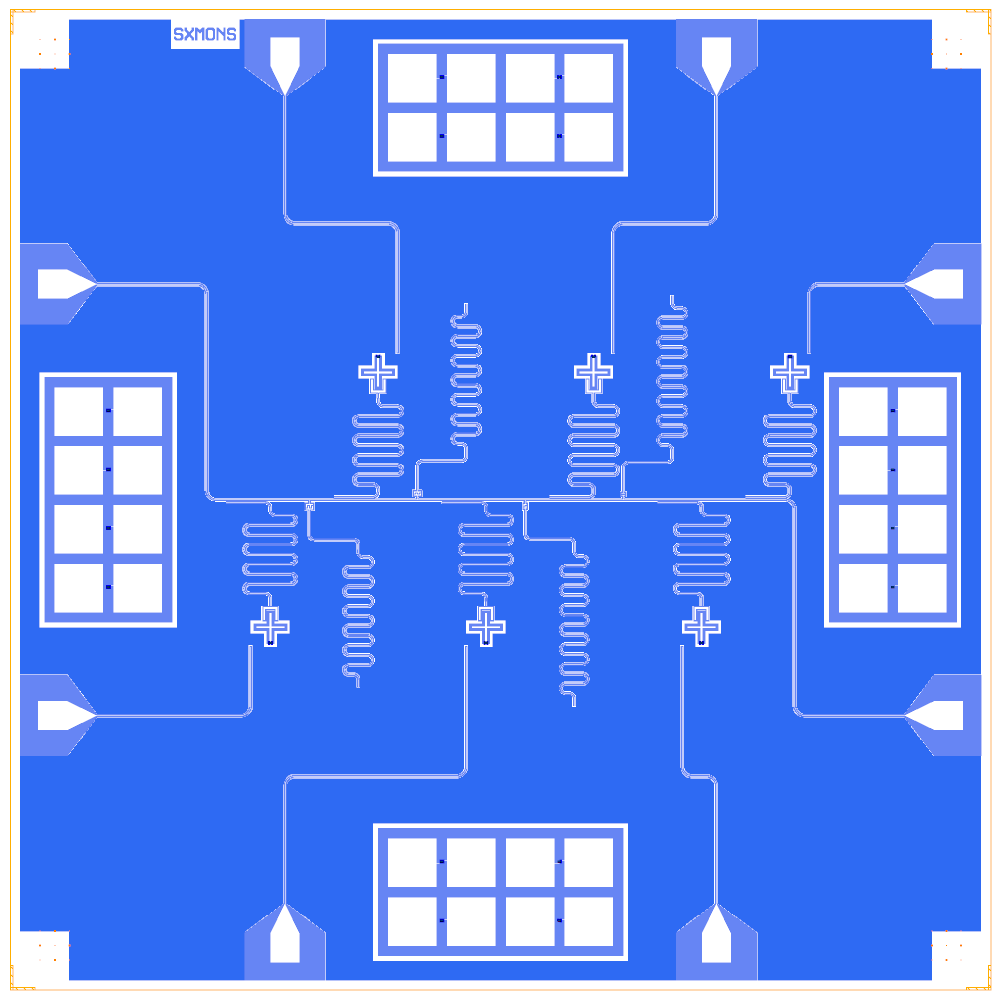

{'TR0': 5200.0, 'TR1': 5400.0, 'TR2': 5600.0, 'TR3': 5800.0, 'RR0': 5000.0, 'RR1': 5100.0, 'RR2': 5200.0, 'RR3': 5300.0, 'RR4': 5400.0, 'RR5': 5500.0}


In [9]:
with d.batch():
    for i, (n, (x, y, r)) in enumerate(qpos.items()):
        xc = x - 225                                          # coupler centre: from the qubit's x towards -x
        seg = next(f"FL{k}" for k, t in enumerate(tee_x + [1e9]) if xc < t)
        d.route(f"RR{i}", qb[n].cplr1, d[seg].hanger(near=(xc, 5000), length=450, side="left" if r else "right",
                                                    ground_gap=5, direction="backward"), meander=5000 + 100 * i, r=50)
    for i, (launcher, n, dy) in enumerate((("NW", "QB0", -1300), ("NE", "QB1", -1300), ("EN", "QB2", 0),
                                           ("WS", "QB3", 0), ("SW", "QB4", 1300), ("SE", "QB5", 1300))):
        (lx, ly), (px, py) = port_xy(d, f"chip.{launcher}"), port_xy(d, f"{n}.drive")
        d.route(f"CL{i}", f"chip.{launcher}", qb[n].drive,
                nodes=[(lx, ly + dy), (px, ly + dy)] if dy else [(px, ly)], term2=6)
snap(d, STEPS / "4_routes.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)
print({k: round(v, 1) for k, v in d.result.route_lengths().items() if k.startswith(("RR", "TR"))})

**Sim groups, centring, save.** One sim group per qubit with its readout (Q3D C-matrix + eigenmode/EPR, 300 µm
margin). `center_in_die` confirms the content is centred (no shift); `singlexmons.json` is then saved.

In [10]:
for i, n in enumerate(qpos):
    d.sim_group(f"{n}_RR{i}", [n, f"RR{i}"], margin_um=300, analyses=["q3d_cmatrix", "eigenmode_epr"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "singlexmons.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)


<Designer singlexmons: 18 instances, 21 routes, live=False> → examples\designs\kqc\singlexmons.json


## 7 · DRC

**Errors** make the build unfit for fab, **warnings** are notes to read, **PDK design warnings** (`pad_edge`,
`pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins and are never enforced. `pdk_rn` judges the
device R_n (a SQUID's two junctions in parallel: 45 kΩ here, inside the window). The 12 `dangling_port` warnings are
couplers 0 and 2 of each Swissmon: zero length (`cpl_length=[0, 140, 0]`) and unused, as in KQC.

In [11]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 12 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 12 | QB0.cplr0 is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 6 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

Swissmon → island node (C and SQUID to ground) plus a coupler node for coupler 1 (C_g to the island, C to
ground). Each readout route → a λ/4 `TLres` at the coupler node plus a `HANGER` κ element to the feedline node.
The charge lines are drive controls; the test resonators are λ/4 `TLres` from the capacitors' far ports; the
launchers WN and ES are the feedline's 50 Ω ports.

In [12]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**QB0 and RR0 ports → nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(("QB0.", "RR0")))))

**24 nodes · 66 branches · 6 controls · 12 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `QB0` | `QB0.island` |
| `QB0.cplr1` | `QB0.cplr1` |
| `QB1` | `QB1.island` |
| `QB1.cplr1` | `QB1.cplr1` |
| `QB2` | `QB2.island` |
| `QB2.cplr1` | `QB2.cplr1` |
| `QB3` | `QB3.island` |
| `QB3.cplr1` | `QB3.cplr1` |
| `QB4` | `QB4.island` |
| `QB4.cplr1` | `QB4.cplr1` |
| `QB5` | `QB5.island` |
| `QB5.cplr1` | `QB5.cplr1` |
| `T0.t` | `T0.t`, `T1.t`, `T2.t`, `T3.t`, `C0.b`, `C1.b`, `C2.b`, `C3.b`, `chip.WN`, `chip.ES` |
| `C0.a` | `C0.a` |
| `C1.a` | `C1.a` |
| `C2.a` | `C2.a` |
| `C3.a` | `C3.a` |
| `chip.NW` | `chip.NW` |
| `chip.NE` | `chip.NE` |
| `chip.EN` | `chip.EN` |
| `chip.WS` | `chip.WS` |
| `chip.SW` | `chip.SW` |
| `chip.SE` | `chip.SE` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_QB0` | C | `QB0` – `gnd` | 62.4 fF |
| `J_QB0` | SQUID | `QB0` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB0_cplr1` | C | `QB0` – `QB0.cplr1` | 4.4 fF |
| `Cc_QB0_cplr1` | C | `QB0.cplr1` – `gnd` | 76.9 fF |
| `C_QB1` | C | `QB1` – `gnd` | 62.4 fF |
| `J_QB1` | SQUID | `QB1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB1_cplr1` | C | `QB1` – `QB1.cplr1` | 4.4 fF |
| `Cc_QB1_cplr1` | C | `QB1.cplr1` – `gnd` | 76.9 fF |
| `C_QB2` | C | `QB2` – `gnd` | 62.4 fF |
| `J_QB2` | SQUID | `QB2` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB2_cplr1` | C | `QB2` – `QB2.cplr1` | 4.4 fF |
| `Cc_QB2_cplr1` | C | `QB2.cplr1` – `gnd` | 76.9 fF |
| `C_QB3` | C | `QB3` – `gnd` | 62.4 fF |
| `J_QB3` | SQUID | `QB3` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB3_cplr1` | C | `QB3` – `QB3.cplr1` | 4.4 fF |
| `Cc_QB3_cplr1` | C | `QB3.cplr1` – `gnd` | 76.9 fF |
| `C_QB4` | C | `QB4` – `gnd` | 62.4 fF |
| `J_QB4` | SQUID | `QB4` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB4_cplr1` | C | `QB4` – `QB4.cplr1` | 4.4 fF |
| `Cc_QB4_cplr1` | C | `QB4.cplr1` – `gnd` | 76.9 fF |
| `C_QB5` | C | `QB5` – `gnd` | 62.4 fF |
| `J_QB5` | SQUID | `QB5` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB5_cplr1` | C | `QB5` – `QB5.cplr1` | 4.4 fF |
| `Cc_QB5_cplr1` | C | `QB5.cplr1` – `gnd` | 76.9 fF |
| `C_C0` | C | `C0.a` – `T0.t` | 10.8 fF |
| `C_C0_a` | C | `C0.a` – `gnd` | 9.7 fF |
| `C_C0_b` | C | `T0.t` – `gnd` | 9.7 fF |
| `C_C1` | C | `C1.a` – `T0.t` | 7.53 fF |
| `C_C1_a` | C | `C1.a` – `gnd` | 8.5 fF |
| `C_C1_b` | C | `T0.t` – `gnd` | 8.5 fF |
| `C_C2` | C | `C2.a` – `T0.t` | 4.12 fF |
| `C_C2_a` | C | `C2.a` – `gnd` | 5.1 fF |
| `C_C2_b` | C | `T0.t` – `gnd` | 5.1 fF |
| `C_C3` | C | `C3.a` – `T0.t` | 3.11 fF |
| `C_C3_a` | C | `C3.a` – `gnd` | 4.3 fF |
| `C_C3_b` | C | `T0.t` – `gnd` | 4.3 fF |
| `Port_WN` | R | `T0.t` – `gnd` | 50 Ω |
| `Port_ES` | R | `T0.t` – `gnd` | 50 Ω |
| `Port_NW` | R | `chip.NW` – `gnd` | 50 Ω |
| `Port_NE` | R | `chip.NE` – `gnd` | 50 Ω |
| `Port_EN` | R | `chip.EN` – `gnd` | 50 Ω |
| `Port_WS` | R | `chip.WS` – `gnd` | 50 Ω |
| `Port_SW` | R | `chip.SW` – `gnd` | 50 Ω |
| `Port_SE` | R | `chip.SE` – `gnd` | 50 Ω |
| `Cd_QB0` | C | `QB0` – `chip.NW` | 0.1 fF |
| `Cd_QB1` | C | `QB1` – `chip.NE` | 0.1 fF |
| `Cd_QB2` | C | `QB2` – `chip.EN` | 0.1 fF |
| `Cd_QB3` | C | `QB3` – `chip.WS` | 0.1 fF |
| `Cd_QB4` | C | `QB4` – `chip.SW` | 0.1 fF |
| `Cd_QB5` | C | `QB5` – `chip.SE` | 0.1 fF |
| `TR0` | TLres | `C0.a` – `gnd` | lambda/4, 5200 µm, 6.059 GHz |
| `TR1` | TLres | `C1.a` – `gnd` | lambda/4, 5400 µm, 5.835 GHz |
| `TR2` | TLres | `C2.a` – `gnd` | lambda/4, 5600 µm, 5.627 GHz |
| `TR3` | TLres | `C3.a` – `gnd` | lambda/4, 5800 µm, 5.433 GHz |
| `RR0` | TLres | `QB0.cplr1` – `gnd` | lambda/4, 5000 µm, 6.302 GHz |
| `K_RR0` | HANGER | `QB0.cplr1` – `T0.t` | κ 0.428 MHz (L 450 µm) |
| `RR1` | TLres | `QB1.cplr1` – `gnd` | lambda/4, 5100 µm, 6.178 GHz |
| `K_RR1` | HANGER | `QB1.cplr1` – `T0.t` | κ 0.403 MHz (L 450 µm) |
| `RR2` | TLres | `QB2.cplr1` – `gnd` | lambda/4, 5200 µm, 6.059 GHz |
| `K_RR2` | HANGER | `QB2.cplr1` – `T0.t` | κ 0.38 MHz (L 450 µm) |
| `RR3` | TLres | `QB3.cplr1` – `gnd` | lambda/4, 5300 µm, 5.945 GHz |
| `K_RR3` | HANGER | `QB3.cplr1` – `T0.t` | κ 0.359 MHz (L 450 µm) |
| `RR4` | TLres | `QB4.cplr1` – `gnd` | lambda/4, 5400 µm, 5.835 GHz |
| `K_RR4` | HANGER | `QB4.cplr1` – `T0.t` | κ 0.34 MHz (L 450 µm) |
| `RR5` | TLres | `QB5.cplr1` – `gnd` | lambda/4, 5500 µm, 5.729 GHz |
| `K_RR5` | HANGER | `QB5.cplr1` – `T0.t` | κ 0.322 MHz (L 450 µm) |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `CL0` | drive | `J_QB0` | `CL0` | 3684 |
| `CL1` | drive | `J_QB1` | `CL1` | 3584 |
| `CL2` | drive | `J_QB2` | `CL2` | 1627 |
| `CL3` | drive | `J_QB3` | `CL3` | 2227 |
| `CL4` | drive | `J_QB4` | `CL4` | 4384 |
| `CL5` | drive | `J_QB5` | `CL5` | 2884 |

**Unconnected ports:** `QB0.cplr0`, `QB0.cplr2`, `QB1.cplr0`, `QB1.cplr2`, `QB2.cplr0`, `QB2.cplr2`, `QB3.cplr0`, `QB3.cplr2`, `QB4.cplr0`, `QB4.cplr2`, `QB5.cplr0`, `QB5.cplr2`

**Builder notes:**

- QB0.cplr0: cpl_length 0 (no coupler), its port ends on ground
- QB0.cplr2: cpl_length 0 (no coupler), its port ends on ground
- QB1.cplr0: cpl_length 0 (no coupler), its port ends on ground
- QB1.cplr2: cpl_length 0 (no coupler), its port ends on ground
- QB2.cplr0: cpl_length 0 (no coupler), its port ends on ground
- QB2.cplr2: cpl_length 0 (no coupler), its port ends on ground
- QB3.cplr0: cpl_length 0 (no coupler), its port ends on ground
- QB3.cplr2: cpl_length 0 (no coupler), its port ends on ground
- QB4.cplr0: cpl_length 0 (no coupler), its port ends on ground
- QB4.cplr2: cpl_length 0 (no coupler), its port ends on ground
- QB5.cplr0: cpl_length 0 (no coupler), its port ends on ground
- QB5.cplr2: cpl_length 0 (no coupler), its port ends on ground

**QB0 and RR0 ports → nodes:**

| port | node |
|---|---|
| `QB0.cplr0` | `gnd` |
| `QB0.cplr1` | `QB0.cplr1` |
| `QB0.cplr2` | `gnd` |
| `QB0.drive` | `control:drive` |
| `QB0.flux` | `control:flux` |

## 9 · LOM simulation

The six qubit / readout pairs share only the feedline, so each pair is its own sub-circuit
(`d.lom(select=[qubit, resonator])`, the feedline kept as a 25 Ω load): QuCat normal modes and κ, then the
QuTiP-dressed f_q, α, f_r and χ. With the PDK SQUIDs f_q ≈ 6.5 GHz (KQC's assumed 16 nH gave ≈ 4.5 GHz), now
**above** the ≈ 5.2–5.7 GHz readouts: the qubits and readouts swap order, so χ changes sign compared with the
source. The test resonators are listed with their bare λ/4 frequency.

In [13]:
pairs = {f"{n}+RR{i}": [n, f"RR{i}"] for i, n in enumerate(qpos)}
results = simulate_groups(d, pairs)
display(Markdown(groups_md(results)))
display(Markdown("**QB0 + RR0 normal modes (QuCat):**\n\n" + modes_md(results["QB0+RR0"])))
display(Markdown("| test resonator | length (µm) | bare f (GHz) |\n|---|---|---|\n" + "\n".join(
    f"| {n} | {b.value['length_um']:.0f} | {b.value['f_GHz']:.4f} |"
    for n, b in lb.model.branches.items() if n.startswith("TR"))))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| QB0+RR0 | QB0 | 6.5419 | -255.2 | RR0 | 5.6552 | 0.276 | -3.92 |
| QB1+RR1 | QB1 | 6.5412 | -256.3 | RR1 | 5.5555 | 0.263 | -2.89 |
| QB2+RR2 | QB2 | 6.5406 | -256.9 | RR2 | 5.4591 | 0.25 | -2.21 |
| QB3+RR3 | QB3 | 6.5401 | -257.4 | RR3 | 5.366 | 0.238 | -1.74 |
| QB4+RR4 | QB4 | 6.5397 | -257.8 | RR4 | 5.2759 | 0.227 | -1.4 |
| QB5+RR5 | QB5 | 6.5394 | -258 | RR5 | 5.1888 | 0.216 | -1.15 |

**QB0 + RR0 normal modes (QuCat):**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| RR0 | resonator | 5.6563 | 0.276 | 0.0 | RR0 1.00 |
| QB0 | qubit | 6.7869 | 0.00228 | 235.3 | J_QB0 1.00 |

| test resonator | length (µm) | bare f (GHz) |
|---|---|---|
| TR0 | 5200 | 6.0594 |
| TR1 | 5400 | 5.8349 |
| TR2 | 5600 | 5.6265 |
| TR3 | 5800 | 5.4325 |

## 10 · FEM: send the jobs

Per sim group a Q3D C-matrix job and an eigenmode / EPR job (every line leaving the box ends in a port, the
junction is a lumped port; the ground grid is removed — simulation exports never have cheese). With
`RUN_FEM = True` and AEDT 2024 R1 (or later) installed, each job is solved in a **new batch, non-graphical** AEDT
(an AEDT window you have open is not touched). CLI: `qcc sim run build/jobs/<job>`.

In [14]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs)))

12 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| QB0_RR0 · q3d_cmatrix | `build/jobs/singlexmons_QB0_RR0_q3d_cmatrix` | 1 · junction · `QB0.junction`<br>2 · waveguide · `QB0.cplr1`<br>3 · edge · `CL0` | `QB0.island`, `QB0.cplr1`, `CL0` |
| QB0_RR0 · eigenmode_epr | `build/jobs/singlexmons_QB0_RR0_eigenmode_epr` | 1 · junction · `QB0.junction`<br>2 · edge_lumped · `CL0`<br>3 · edge_lumped · `FL0`<br>4 · edge_lumped · `FL2` | `QB0.island`, `CL0`, `FL0`, `FL2` |
| QB1_RR1 · q3d_cmatrix | `build/jobs/singlexmons_QB1_RR1_q3d_cmatrix` | 1 · junction · `QB1.junction`<br>2 · waveguide · `QB1.cplr1`<br>3 · edge · `CL1` | `QB1.island`, `QB1.cplr1`, `CL1` |
| QB1_RR1 · eigenmode_epr | `build/jobs/singlexmons_QB1_RR1_eigenmode_epr` | 1 · junction · `QB1.junction`<br>2 · edge_lumped · `CL1`<br>3 · edge_lumped · `FL2`<br>4 · edge_lumped · `FL4` | `QB1.island`, `CL1`, `FL2`, `FL4` |
| QB2_RR2 · q3d_cmatrix | `build/jobs/singlexmons_QB2_RR2_q3d_cmatrix` | 1 · junction · `QB2.junction`<br>2 · waveguide · `QB2.cplr1`<br>3 · edge · `CL2` | `QB2.island`, `QB2.cplr1`, `CL2` |
| QB2_RR2 · eigenmode_epr | `build/jobs/singlexmons_QB2_RR2_eigenmode_epr` | 1 · junction · `QB2.junction`<br>2 · edge_lumped · `CL2`<br>3 · edge_lumped · `FL4`<br>4 · edge_lumped · `FL4` | `QB2.island`, `CL2`, `FL4`, `FL4#2` |
| QB3_RR3 · q3d_cmatrix | `build/jobs/singlexmons_QB3_RR3_q3d_cmatrix` | 1 · junction · `QB3.junction`<br>2 · waveguide · `QB3.cplr1`<br>3 · edge · `CL3` | `QB3.island`, `QB3.cplr1`, `CL3` |
| QB3_RR3 · eigenmode_epr | `build/jobs/singlexmons_QB3_RR3_eigenmode_epr` | 1 · junction · `QB3.junction`<br>2 · edge_lumped · `CL3`<br>3 · edge_lumped · `FL0`<br>4 · edge_lumped · `FL1` | `QB3.island`, `CL3`, `FL0`, `FL1` |
| QB4_RR4 · q3d_cmatrix | `build/jobs/singlexmons_QB4_RR4_q3d_cmatrix` | 1 · junction · `QB4.junction`<br>2 · waveguide · `QB4.cplr1`<br>3 · edge · `CL4` | `QB4.island`, `QB4.cplr1`, `CL4` |
| QB4_RR4 · eigenmode_epr | `build/jobs/singlexmons_QB4_RR4_eigenmode_epr` | 1 · junction · `QB4.junction`<br>2 · edge_lumped · `CL4`<br>3 · edge_lumped · `FL1`<br>4 · edge_lumped · `FL3` | `QB4.island`, `CL4`, `FL1`, `FL3` |
| QB5_RR5 · q3d_cmatrix | `build/jobs/singlexmons_QB5_RR5_q3d_cmatrix` | 1 · junction · `QB5.junction`<br>2 · waveguide · `QB5.cplr1`<br>3 · edge · `CL5` | `QB5.island`, `QB5.cplr1`, `CL5` |
| QB5_RR5 · eigenmode_epr | `build/jobs/singlexmons_QB5_RR5_eigenmode_epr` | 1 · junction · `QB5.junction`<br>2 · edge_lumped · `CL5`<br>3 · edge_lumped · `FL4`<br>4 · edge_lumped · `FL4` | `QB5.island`, `CL5`, `FL4`, `FL4#2` |

## 11 · Bring the results back

A solved job has `results/results.json`; `fem_back` fills the LOM from it (`fill(model, design, job)`: C-matrix
values replace the estimates, matched by net name) and compares them; `simulate(filled)` re-runs the LOM.

In [15]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for QB0_RR0 · q3d_cmatrix, QB0_RR0 · eigenmode_epr, QB1_RR1 · q3d_cmatrix, QB1_RR1 · eigenmode_epr, QB2_RR2 · q3d_cmatrix, QB2_RR2 · eigenmode_epr, QB3_RR3 · q3d_cmatrix, QB3_RR3 · eigenmode_epr, QB4_RR4 · q3d_cmatrix, QB4_RR4 · eigenmode_epr, QB5_RR5 · q3d_cmatrix, QB5_RR5 · eigenmode_epr: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

The readout's coupling to the feedline is set by the hanger section: shorten RR0's coupler from 450 to 300 µm,
keeping its end under the qubit (its centre moves from x0 − 225 to x0 − 150).
The coupled-line κ drops (roughly with the square of the coupled length), f_r moves a little (the coupler is part
of the λ/4 line) and χ barely changes. Done on a copy (`design_copy`), so `singlexmons.json` keeps KQC's 450 µm.

In [16]:
d2 = design_copy(DESIGN)
x0 = qpos["QB0"][0]                              # the coupler's far end stays under the qubit (x0)
d2["RR0"].set(to=dict(d2["RR0"].spec["to"], length=300, near=[x0 - 150, 5000]))
after = simulate_groups(d2, {"QB0+RR0": pairs["QB0+RR0"]})
display(Markdown("**RR0 hanger coupler: 450 → 300 µm**\n\n" + params_delta_md({"QB0+RR0": results["QB0+RR0"]}, after)))

**RR0 hanger coupler: 450 → 300 µm**

| parameter | before | after | Δ |
|---|---|---|---|
| `QB0+RR0: RR0.f_GHz` | 5.6552 | 5.6656 | +0.0104 |
| `QB0+RR0: RR0.kappa_MHz` | 0.27644 | 0.12422 | -0.1522 |
| `QB0+RR0: RR0.chi_MHz` | -3.9158 | -4.057 | -0.1412 |
| `QB0+RR0: QB0.f_q_GHz` | 6.5419 | 6.542 | +0.0001023 |
| `QB0+RR0: QB0.alpha_MHz` | -255.23 | -255.09 | +0.1414 |

## 13 · Build and export

`singlexmons.json` is the design: `qcc build examples/designs/kqc/singlexmons.json` writes `build/singlexmons.oas`
+ sidecar. `export_fab` writes the PDK fab layers: 1/0 base etch with the cheese (source `build`: KQC's grid),
the filled 3/0 keep-out (route + 10 µm, component + 24 µm, plus every grid hole), the trilayer layers 2/0 + 4/0 + 50–53/0, airbridges 300/301 if any, and the frame
100/0, 1000/0, 1001/0. `qcc mask examples/designs/kqc/singlexmons.json` writes the complete file (with corner
rounding; `FULL_FAB` here).

For simulation, `build_simulation(..., airbridges=True)` keeps airbridges (default: dropped), and the cheese is
never exported (`setup.geometry` reports what was left out).

In [17]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB0_RR0", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 722059 |
| 2/0 | JJ_STRAIGHT | 22 |
| 3/0 | M3 | 694820 |
| 4/0 | JJ_BENT | 22 |
| 50/0 | HSQ | 88 |
| 51/0 | SPACER_1 | 88 |
| 52/0 | SPACER_2 | 88 |
| 53/0 | SPACER_3 | 88 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 722030 holes on the mask.

→ `build/singlexmons_fab.oas`

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped'}


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'}


## 14 · Snapshots

Full chip; QB0 with its coupler; the QB0 SQUID; the RR0 hanger coupler along the feedline (5 µm ground strip);
the die frame's south-west corner; QB0 in the **fab view** (the mask from step 13: 1/0 with KQC's grid holes, 3/0,
the trilayer layers); and KQC's own `SingleXmons` built stand-alone for comparison. (At full-chip scale KQC's grid fills the ground as one tone; the zooms and the fab view show the holes.)

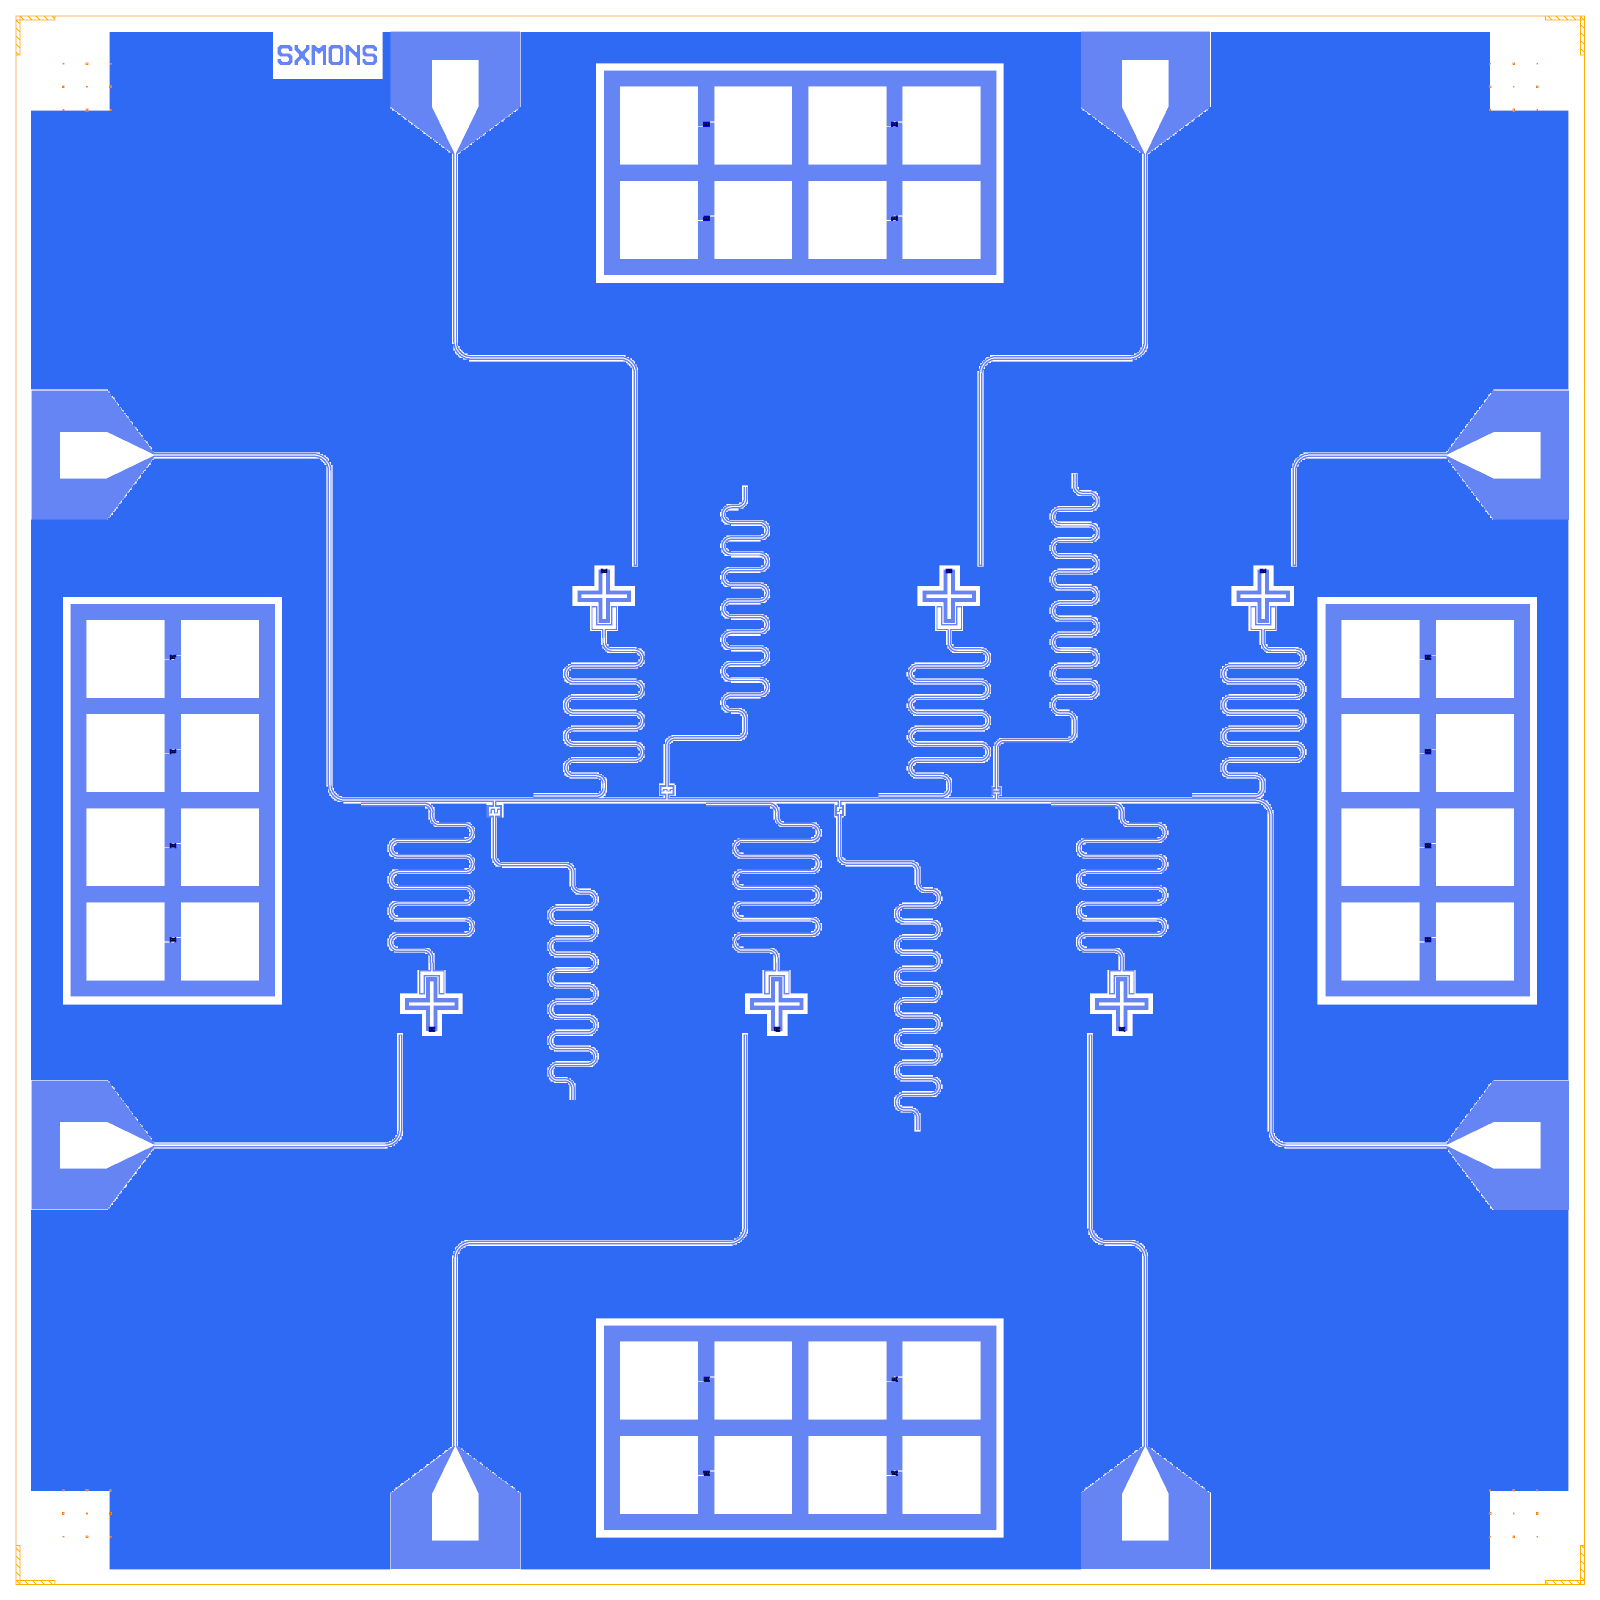

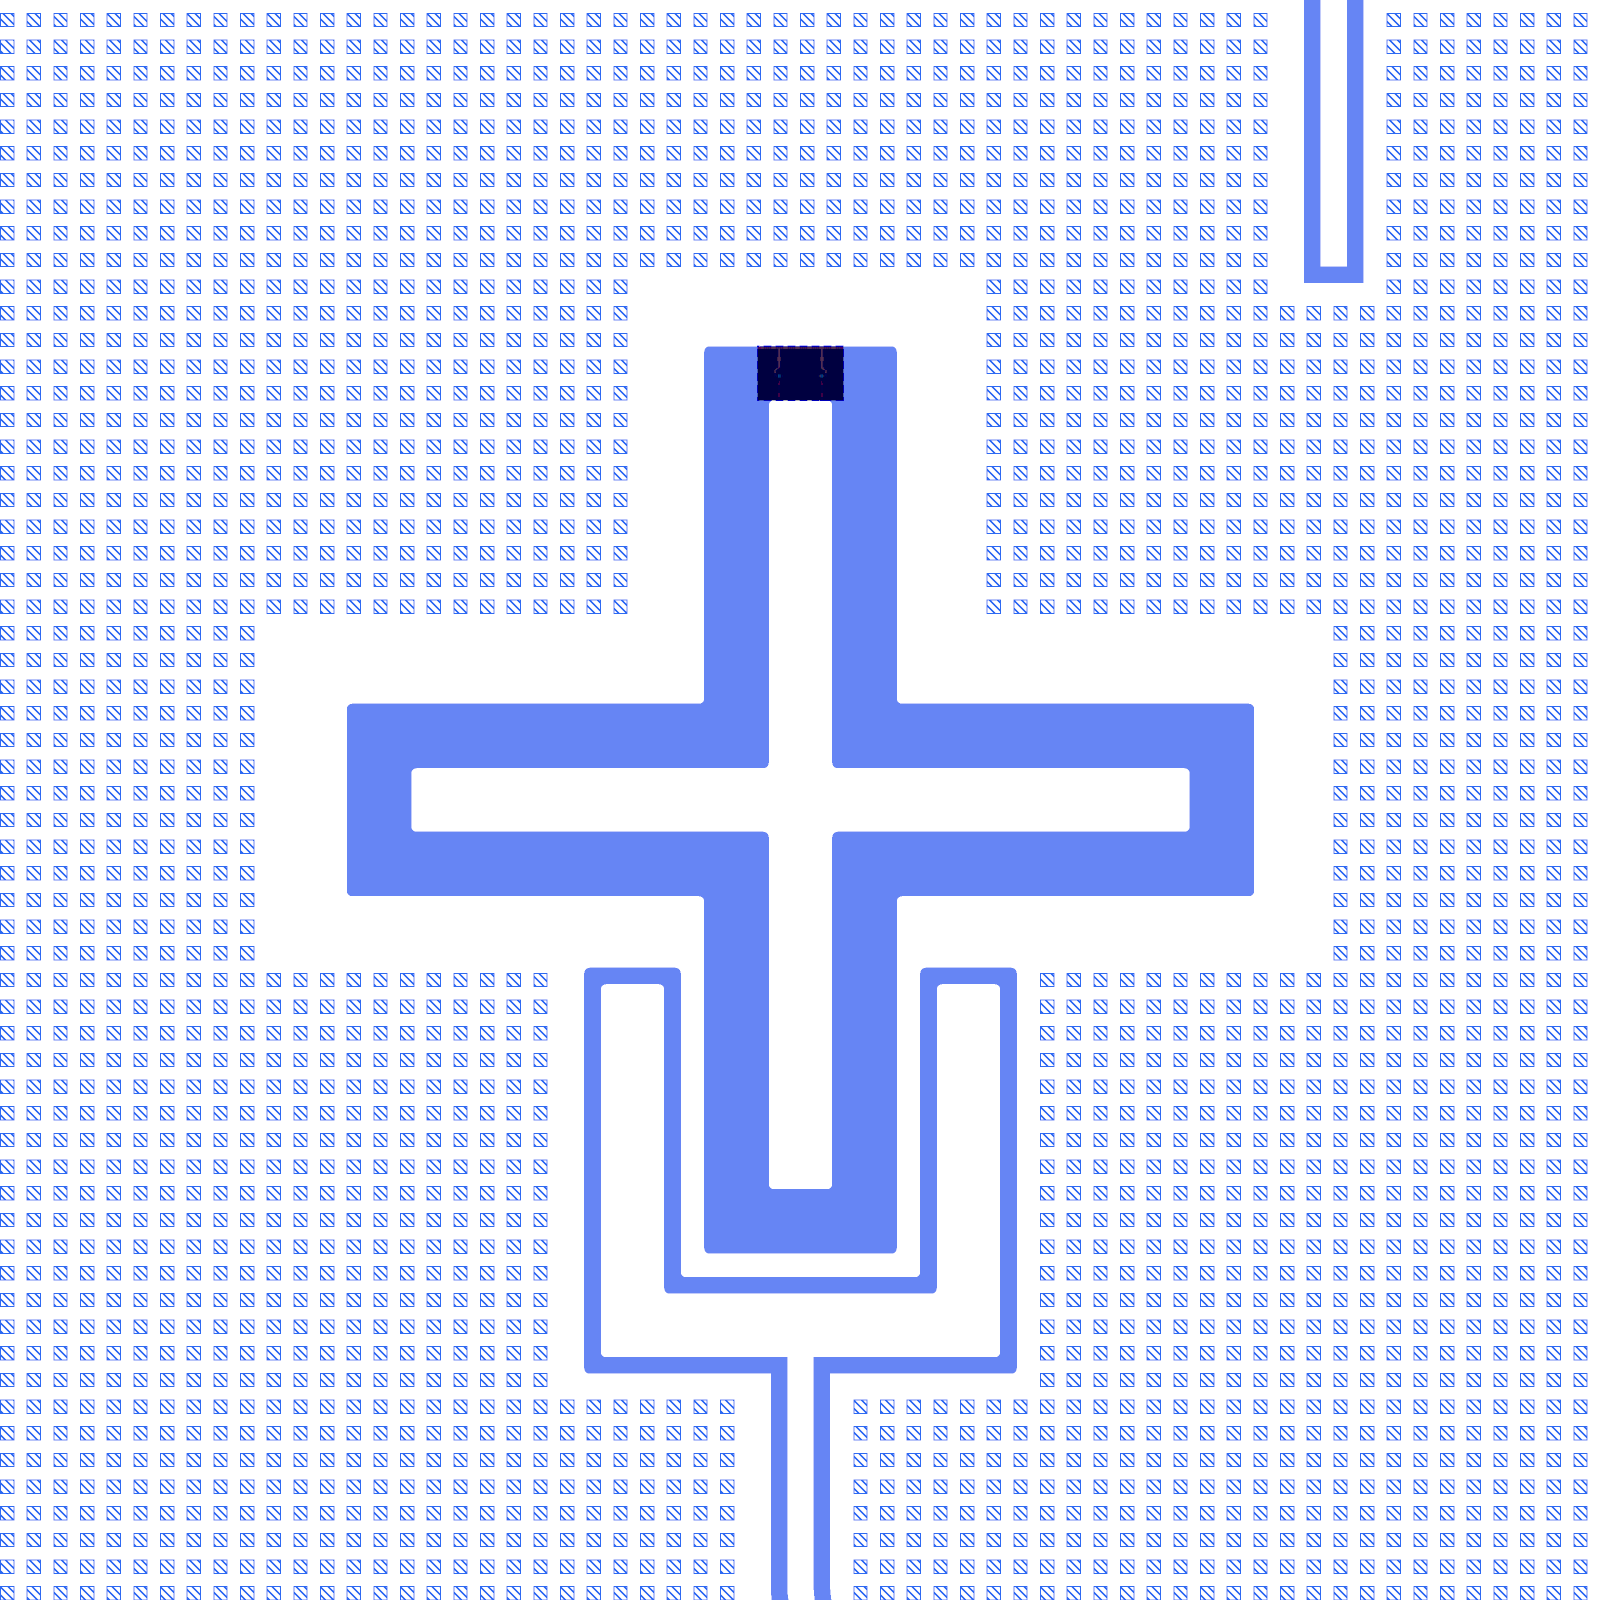

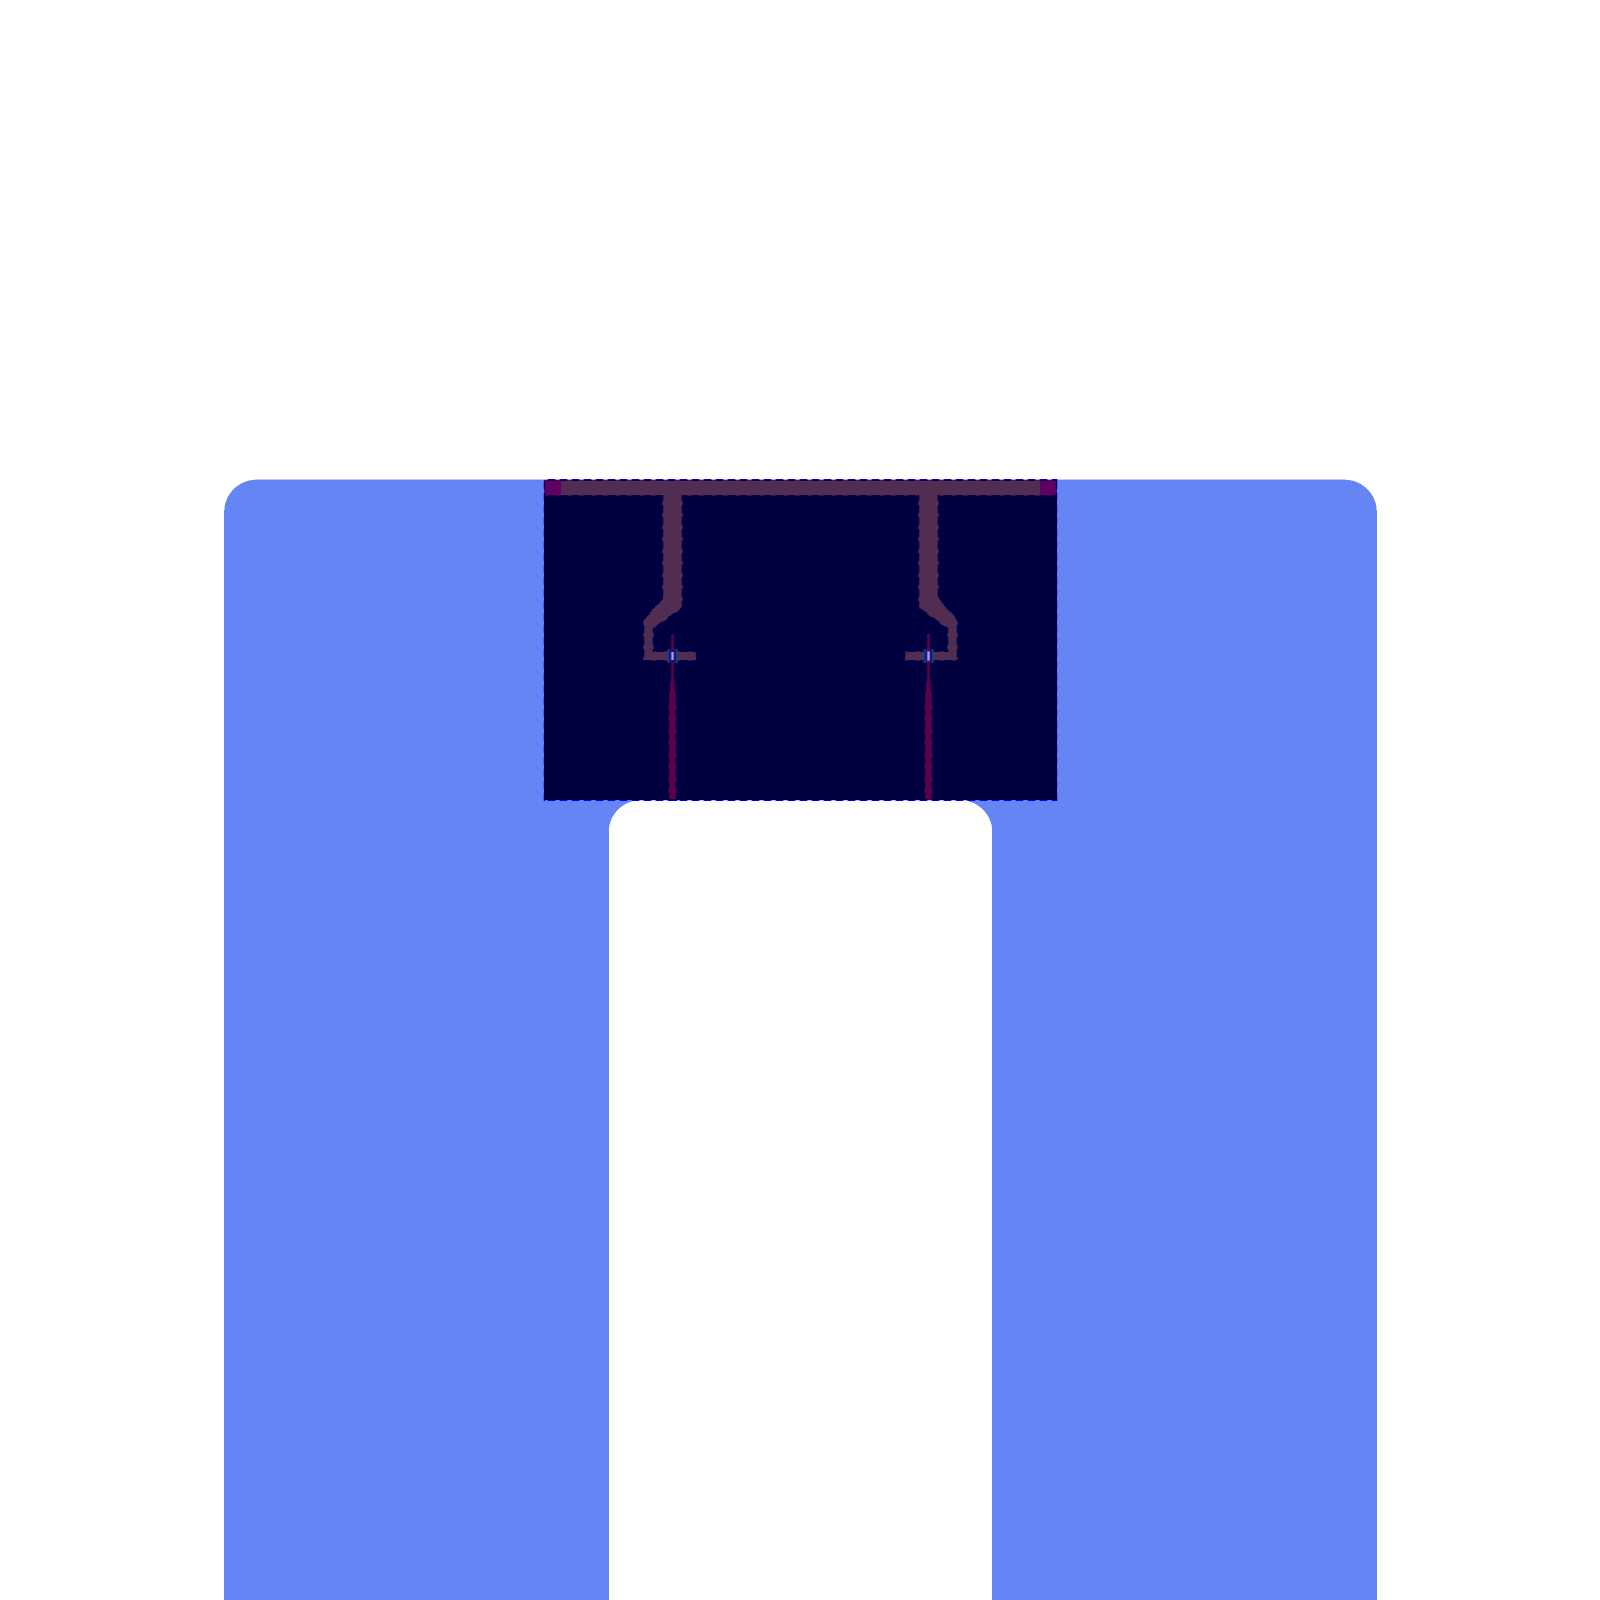

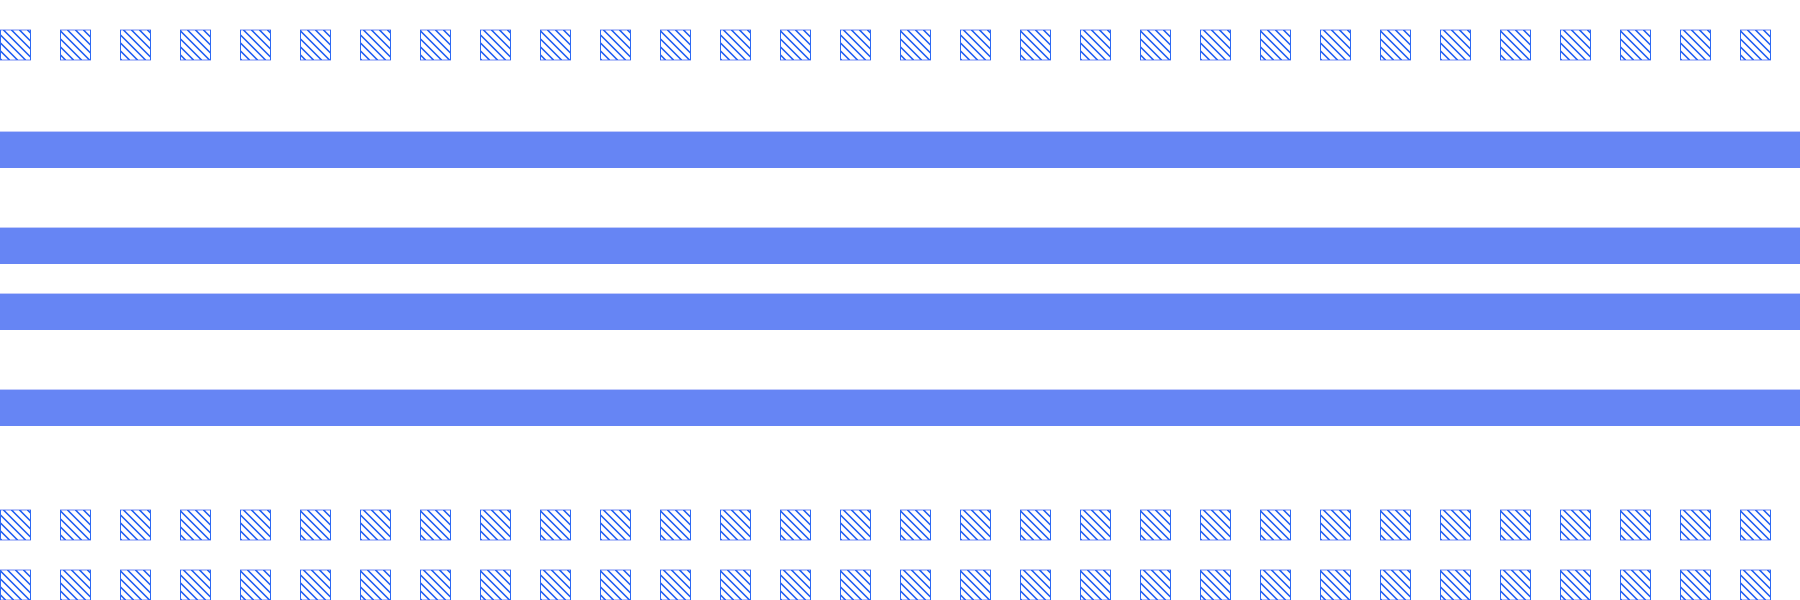

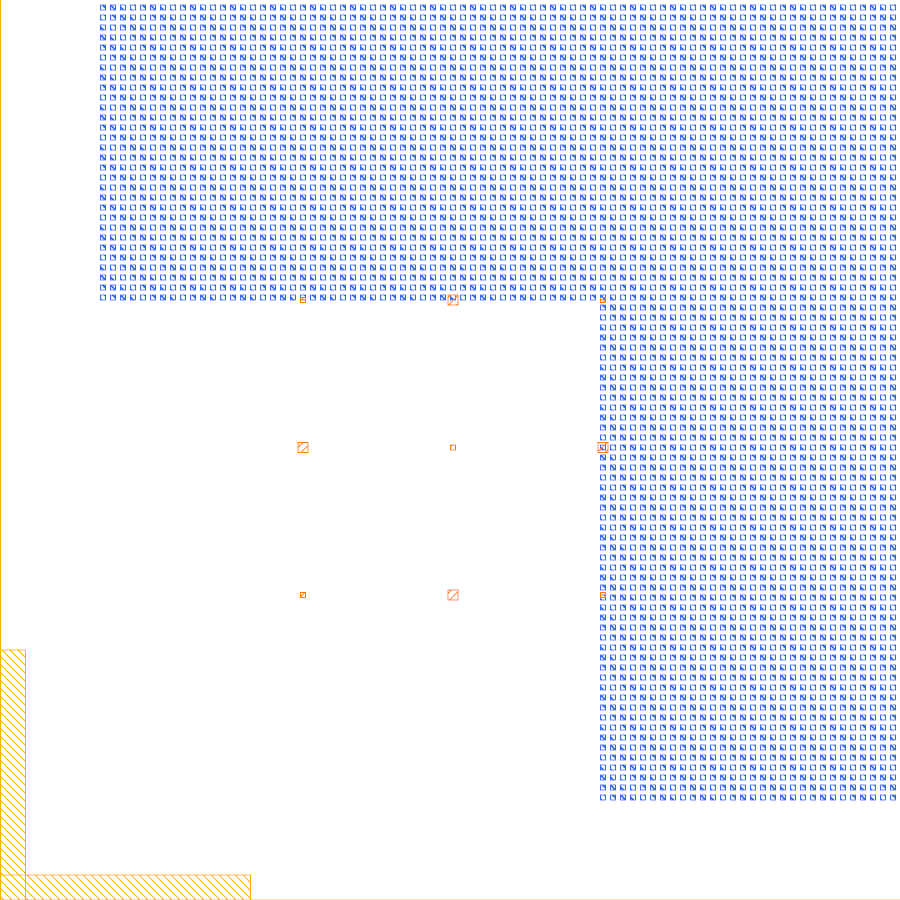

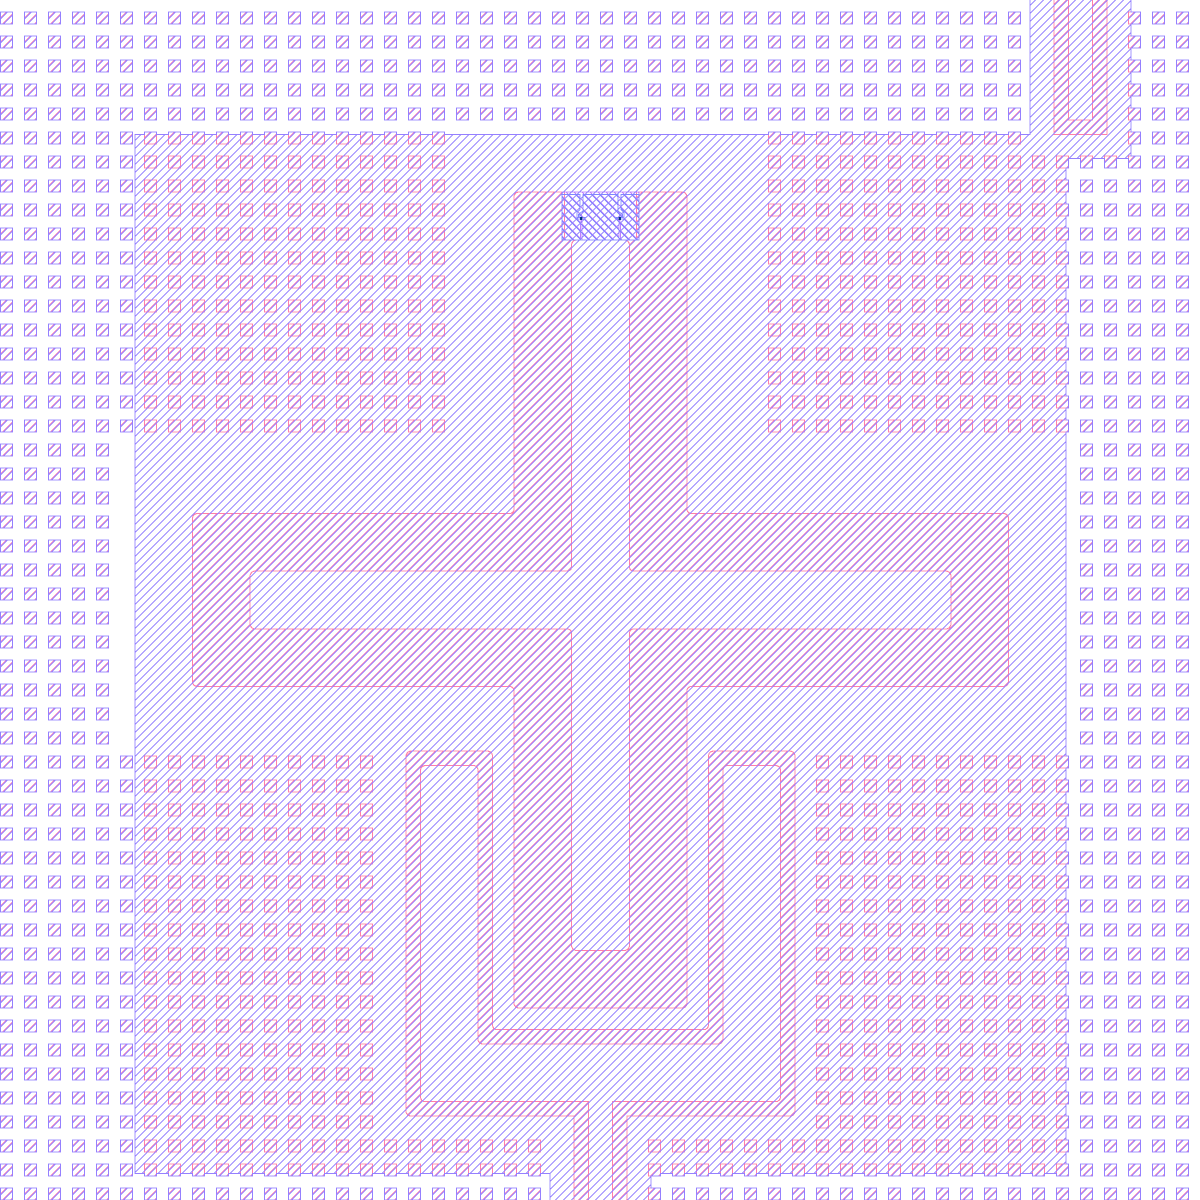

In [18]:
show_snapshot(d, OUT / "singlexmons.png")
x, y, _ = qpos["QB0"]
show_snapshot(d, OUT / "singlexmons_qb0.png", box=(x - 300, y - 300, x + 300, y + 300), width=420)
show_snapshot(d, OUT / "singlexmons_squid.png", box=(x - 50, y + 100, x + 50, y + 200), width=360)
show_snapshot(d, OUT / "singlexmons_coupler.png", box=(x - 450, y - 1340, x - 150, y - 1240), size=(1800, 600), width=540)
show_snapshot(d, OUT / "singlexmons_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "singlexmons_fab.oas", OUT / "singlexmons_fab_qb0.png", box=(x - 250, y - 250, x + 250, y + 250),
          size=(1200, 1200), width=420);

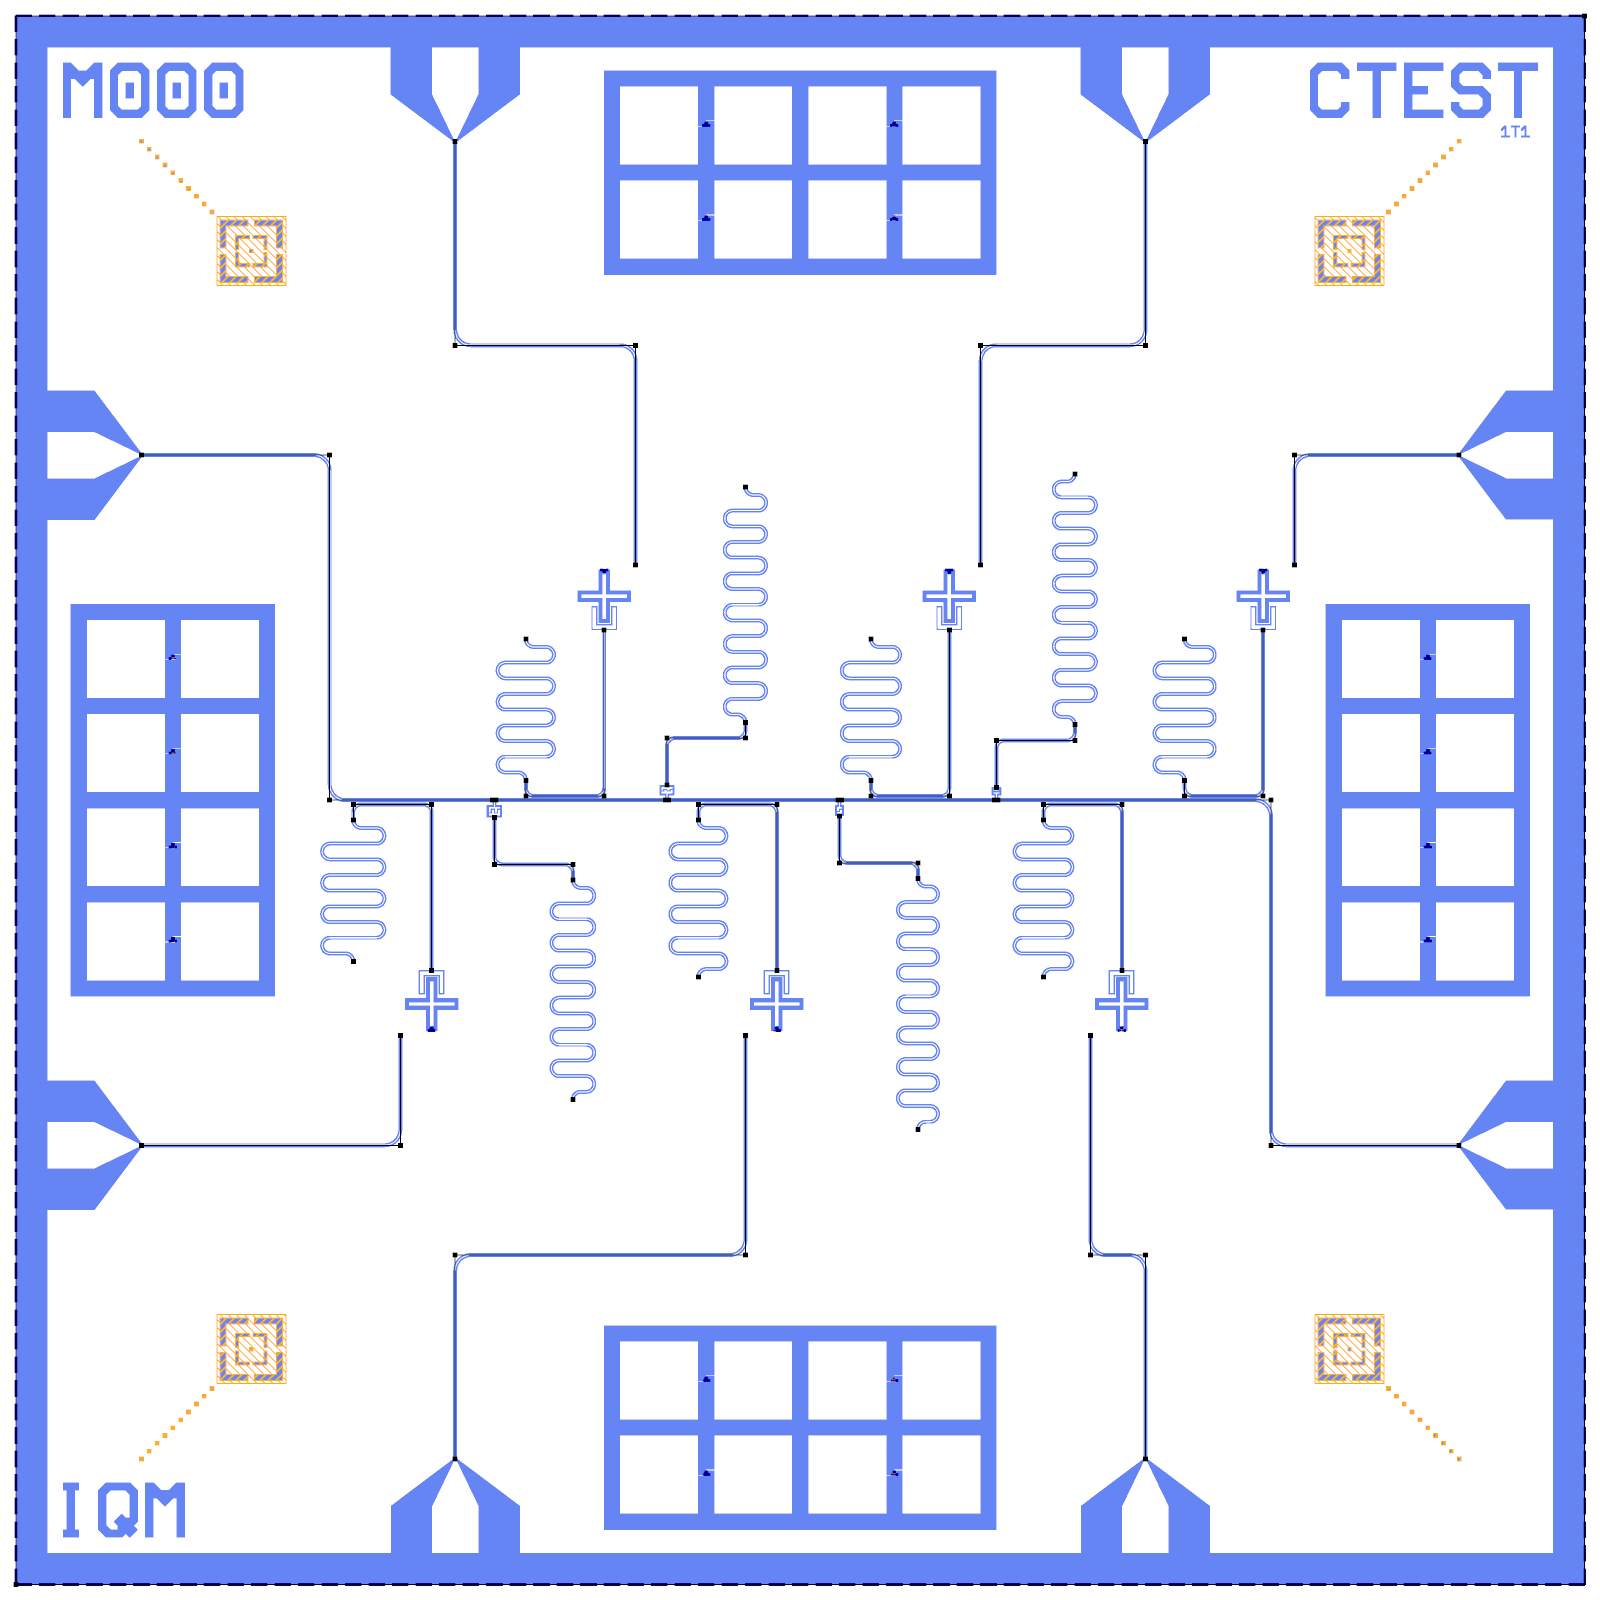

In [19]:
from kqcircuits.chips.single_xmons import SingleXmons
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_singlexmons")
top.insert(pya.DCellInstArray(SingleXmons.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "singlexmons_kqc_original.oas"))
snap_file(Path("build") / "singlexmons_kqc_original.oas", OUT / "singlexmons_kqc.png", box=(-100, -100, 10100, 10100),
          width=420);

## 15 · Summary

| | |
|---|---|
| **matches the source** | the six Swissmons, tees, capacitors, test resonators, junction-test arrays at KQC's positions with KQC's parameters; the feedline path; readout lengths and the 27 µm coupling at KQC's coupler centres; charge lines; KQC's whole-area ground grid |
| **differs (PDK)** | Quantcore die frame; launchers 80 µm further in (outer etch 100 µm from the edge, `frame.pad_edge`); sapphire; trilayer SQUIDs (f_q ≈ 6.5 GHz, above the readouts); hanger couplers anchored by `near=`, corners by the launcher ports |
| **simplified** | readout meander before the coupler; router-fitted test-resonator meanders |
| **PDK design warnings** | as listed in step 7 (the SQUIDs' device R_n, 45 kΩ, is inside the window) |
| **FEM** | 12 jobs (6 × Q3D, 6 × eigenmode/EPR) exported to `build/jobs/singlexmons_*`, not solved here |